In [2]:
import pandas as pd

df = pd.read_csv("../../data/netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
print("Dataset Shape:", df.shape)
print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))

Dataset Shape: (8807, 12)
Total Rows: 8807
Total Columns: 12


In [4]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [5]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_percent = missing_percent[missing_percent > 0].sort_values(ascending=False)

print(missing_percent.round(2))

director      29.91
country        9.44
cast           9.37
date_added     0.11
rating         0.05
duration       0.03
dtype: float64


type
Movie      6131
TV Show    2676
Name: count, dtype: int64


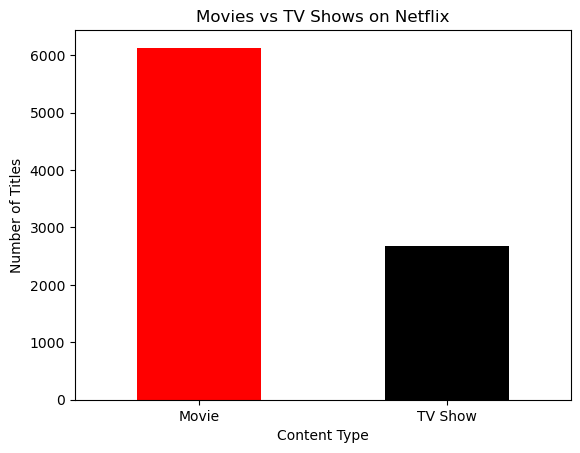

In [7]:
import matplotlib.pyplot as plt

type_counts = df["type"].value_counts()

print(type_counts)

type_counts.plot(kind="bar", color=["red", "black"])
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.show()

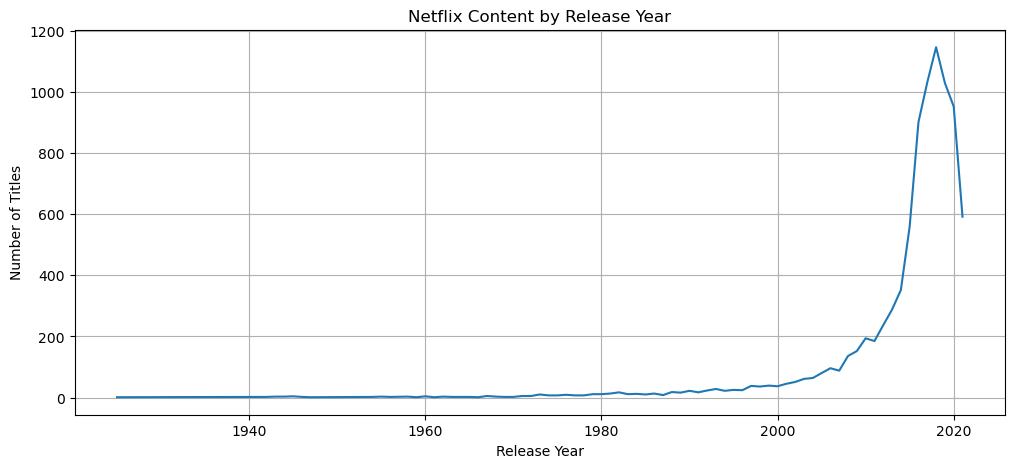

In [8]:
year_counts = df["release_year"].value_counts().sort_index()

year_counts.plot(kind="line", figsize=(12, 5))

plt.title("Netflix Content by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


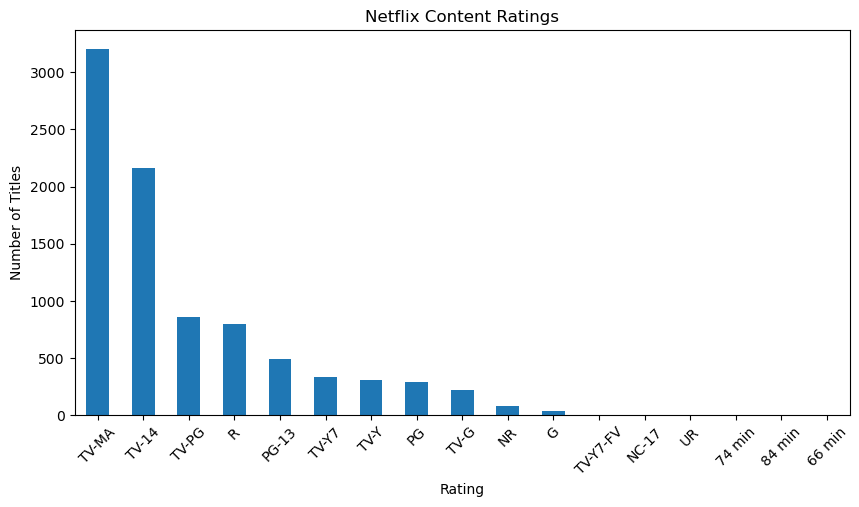

In [9]:
rating_counts = df["rating"].value_counts()

print(rating_counts)

rating_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.show()

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


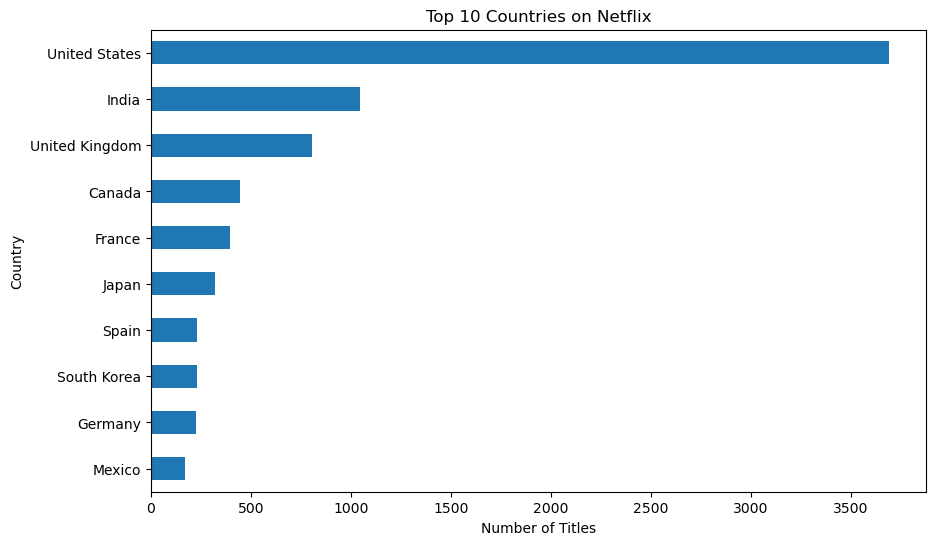

In [10]:
country_counts = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

print(country_counts)

country_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Countries on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.show()

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


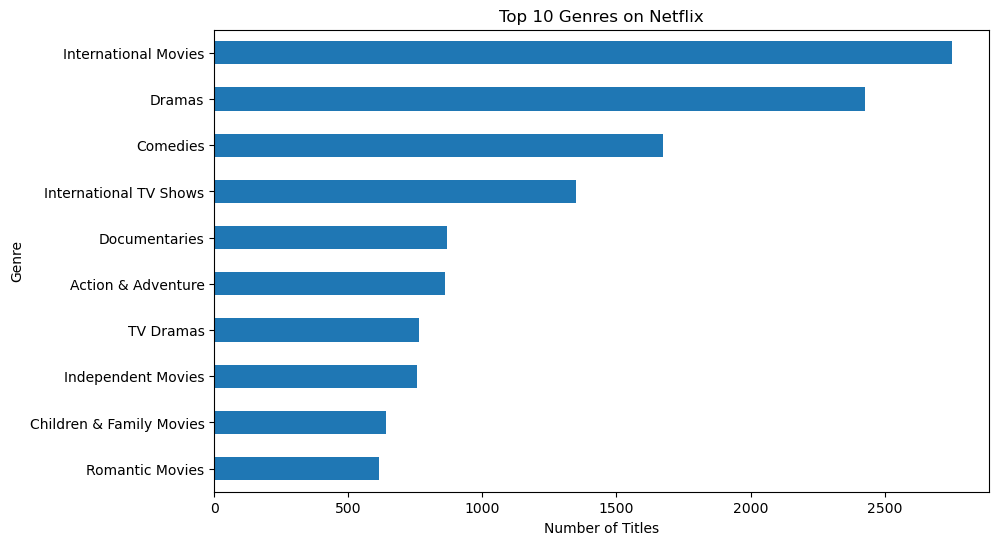

In [11]:
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

print(genre_counts)

genre_counts.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.show()

In [12]:
# Separate Movies and TV Shows
movies = df[df["type"] == "Movie"].copy()
tv_shows = df[df["type"] == "TV Show"].copy()

# Convert movie duration into numbers
movies["duration_minutes"] = (
    movies["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

# Convert TV show duration into numbers
tv_shows["seasons"] = (
    tv_shows["duration"]
    .str.extract(r"(\d+)")
    .astype(float)
)

print("Average Movie Duration:")
print(round(movies["duration_minutes"].mean(), 2), "minutes")

print("\nTV Shows Season Count:")
print(tv_shows["seasons"].value_counts().sort_index())

Average Movie Duration:
99.58 minutes

TV Shows Season Count:
seasons
1.0     1793
2.0      425
3.0      199
4.0       95
5.0       65
6.0       33
7.0       23
8.0       17
9.0        9
10.0       7
11.0       2
12.0       2
13.0       3
15.0       2
17.0       1
Name: count, dtype: int64


In [13]:
print("===== NETFLIX DATA ANALYSIS: KEY INSIGHTS =====")

print("\n1. Total Titles:", len(df))

print("\n2. Movies vs TV Shows:")
print(df["type"].value_counts())

print("\n3. Top 5 Content Ratings:")
print(df["rating"].value_counts().head(5))

print("\n4. Top 5 Countries:")
print(
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(5)
)

print("\n5. Top 5 Genres:")
print(
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(5)
)

===== NETFLIX DATA ANALYSIS: KEY INSIGHTS =====

1. Total Titles: 8807

2. Movies vs TV Shows:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

3. Top 5 Content Ratings:
rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
Name: count, dtype: int64

4. Top 5 Countries:
country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Name: count, dtype: int64

5. Top 5 Genres:
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64


In [1]:
import pandas as pd

df = pd.read_csv("data/netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
print("===== NETFLIX DATA ANALYSIS SUMMARY =====")

print(f"Total Titles: {len(df)}")

print("\nContent Type Distribution:")
print(df["type"].value_counts())

print("\nTop 5 Genres:")
print(
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(5)
)

print("\nAnalysis Completed Successfully!")

===== NETFLIX DATA ANALYSIS SUMMARY =====
Total Titles: 8807

Content Type Distribution:
type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Top 5 Genres:
listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

Analysis Completed Successfully!
